In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Patient Data.csv")


In [10]:
#Q1
print("Q1: Three Numeric Columns")
print("1. Age")
print("2. BMI")
print("3. Treatment_Cost_INR\n")

print("Q1: Three Categorical Columns")
print("1. Gender")
print("2. Department")
print("3. Admission_Type")

Q1: Three Numeric Columns
1. Age
2. BMI
3. Treatment_Cost_INR

Q1: Three Categorical Columns
1. Gender
2. Department
3. Admission_Type


In [11]:
#Q2
missing_percentage = df.isna().mean() * 100
print("Missing-value percentages:")
print(missing_percentage)
duplicate_count = df.duplicated().sum()
print("\nNumber of duplicate records:", duplicate_count)

Missing-value percentages:
Encounter_ID             0.0
Patient_ID               0.0
Admission_Date           0.0
Discharge_Date           0.0
Age                      0.0
Gender                   0.0
Blood_Type               0.0
Department               0.0
Diagnosis                0.0
Admission_Type           0.0
Length_of_Stay_Days      0.0
Systolic_BP_mmHg         0.0
Diastolic_BP_mmHg        0.0
Heart_Rate_bpm           0.0
Temperature_C            0.0
BMI                      2.5
Blood_Glucose_mg_dL      2.4
Cholesterol_mg_dL        4.0
Oxygen_Saturation_pct    0.0
Smoking_Status           0.0
Insurance_Type           0.0
Treatment_Cost_INR       0.0
Readmitted_30_Days       0.0
Discharge_Status         0.0
dtype: float64

Number of duplicate records: 0


In [12]:
#Q3
mean_cost = df["Treatment_Cost_INR"].mean()
median_cost = df["Treatment_Cost_INR"].median()
print("Mean Treatment Cost:", mean_cost)
print("Median Treatment Cost:", median_cost)
if mean_cost > median_cost:
    print("The treatment cost distribution is likely right-skewed (positively skewed).")
elif mean_cost < median_cost:
    print("The treatment cost distribution is likely left-skewed (negatively skewed).")
else:
    print("The treatment cost distribution is approximately symmetric.")

Mean Treatment Cost: 60742.7
Median Treatment Cost: 55400.0
The treatment cost distribution is likely right-skewed (positively skewed).


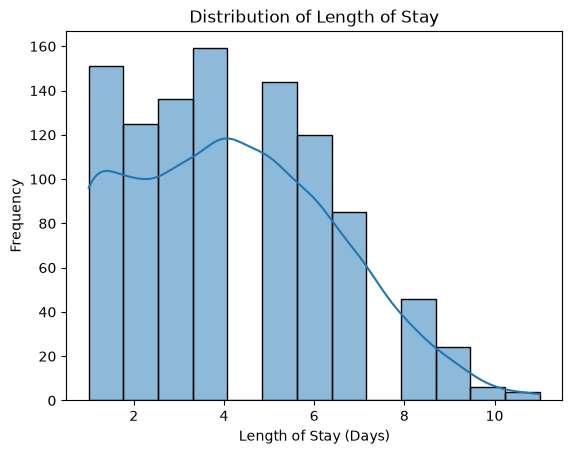

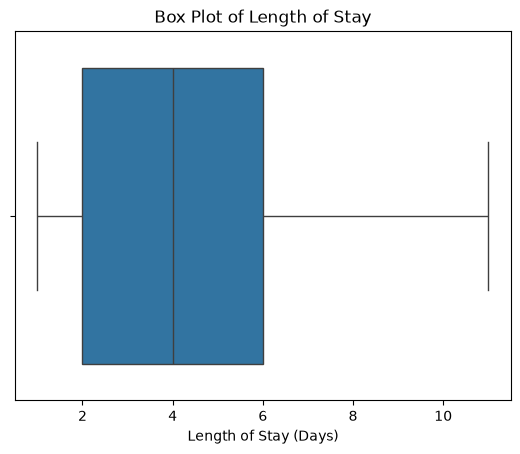

In [13]:
#Q4
sns.histplot(data=df, x="Length_of_Stay_Days", kde=True)
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Frequency")
plt.title("Distribution of Length of Stay")
plt.show()
sns.boxplot(data=df, x="Length_of_Stay_Days")
plt.xlabel("Length of Stay (Days)")
plt.title("Box Plot of Length of Stay")
plt.show()

Department
Cardiology          39450.0
Endocrinology       42450.0
Gastroenterology    30600.0
General Medicine    37950.0
General Surgery     91700.0
Nephrology          83400.0
Neurology           20700.0
Orthopedics         83600.0
Pulmonology         72600.0
Name: Treatment_Cost_INR, dtype: float64


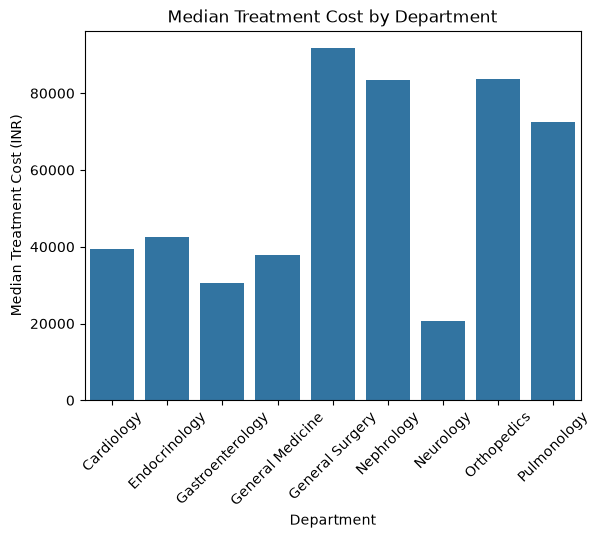

In [15]:
#Q5
median_cost_by_department = df.groupby("Department")["Treatment_Cost_INR"].median()
print(median_cost_by_department)
sns.barplot(x=median_cost_by_department.index, y=median_cost_by_department.values)
plt.xlabel("Department")
plt.ylabel("Median Treatment Cost (INR)")
plt.title("Median Treatment Cost by Department")
plt.xticks(rotation=45)
plt.show()

In [18]:
#Q6
print(df.columns.tolist())
print("\nWaiting_Time and Satisfaction columns are not available in this dataset.")
print("Available related numerical variables include Length_of_Stay_Days and Treatment_Cost_INR.")

['Encounter_ID', 'Patient_ID', 'Admission_Date', 'Discharge_Date', 'Age', 'Gender', 'Blood_Type', 'Department', 'Diagnosis', 'Admission_Type', 'Length_of_Stay_Days', 'Systolic_BP_mmHg', 'Diastolic_BP_mmHg', 'Heart_Rate_bpm', 'Temperature_C', 'BMI', 'Blood_Glucose_mg_dL', 'Cholesterol_mg_dL', 'Oxygen_Saturation_pct', 'Smoking_Status', 'Insurance_Type', 'Treatment_Cost_INR', 'Readmitted_30_Days', 'Discharge_Status']

Q6: Waiting_Time and Satisfaction columns are not available in this dataset.
Available related numerical variables include Length_of_Stay_Days and Treatment_Cost_INR.


In [ ]:
#Q7
df["Cost_Per_Day"] = df["Treatment_Cost_INR"] / df["Length_of_Stay_Days"]
result = df.groupby(["Department", "Admission_Type"])["Cost_Per_Day"].median().unstack()
print(result)
sns.heatmap(result, annot=True, fmt=".0f")
plt.title("Median Treatment Cost per Day by Department and Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Department")
plt.show()

In [20]:
#Q8
print("Five Evidence-Based Insights:")
print("1. BMI has 2.5% missing values, Blood_Glucose_mg_dL has 2.4%, and Cholesterol_mg_dL has 4.0% missing values.")
print("2. The dataset contains 0 duplicate records.")
print("3. Length of stay is positively skewed, with most patients staying around 1 to 6 days.")
print("4. Median treatment cost varies substantially across departments, with General Surgery having the highest median cost.")
print("5. Median treatment cost per day varies across departments and admission types, with General Surgery showing the highest values.")

print("\nTwo Limitations:")
print("1. The dataset does not contain Waiting_Time or Satisfaction columns, so those practice-question relationships could not be directly analyzed.")
print("2. Observed relationships in the EDA do not establish causation, and the analysis may be affected by missing values and other unmeasured factors.")

Five Evidence-Based Insights:
1. BMI has 2.5% missing values, Blood_Glucose_mg_dL has 2.4%, and Cholesterol_mg_dL has 4.0% missing values.
2. The dataset contains 0 duplicate records.
3. Length of stay is positively skewed, with most patients staying around 1 to 6 days.
4. Median treatment cost varies substantially across departments, with General Surgery having the highest median cost.
5. Median treatment cost per day varies across departments and admission types, with General Surgery showing the highest values.

Two Limitations:
1. The dataset does not contain Waiting_Time or Satisfaction columns, so those practice-question relationships could not be directly analyzed.
2. Observed relationships in the EDA do not establish causation, and the analysis may be affected by missing values and other unmeasured factors.
